# Titanic Projesi: Keras ve Deep Learning ile Sınıflandırma

Bu projede Titanic yolcularının bilgilerini (sınıf, cinsiyet, yaş, bilet ücreti, aile ve bindiği liman) kullanarak bir yolcunun kazadan sağ kurtulup kurtulmadığını tahmin eden bir derin öğrenme modeli geliştireceğiz. Derslerdeki Pima Indians Diabetes örneğinin yöntemini izleyeceğiz: Keras ile Sequential model, Dense katmanlar ve iki sınıflı (hayatta kaldı / kalmadı) problem olduğu için son katmanda sigmoid.

5 farklı Keras modeli deneyeceğiz ve karşılaştırma için klasik bir makine öğrenmesi modeli (Logistic Regression) kuracağız. Hedefimiz accuracy > 0.80.

Veri seti: Kaggle Titanic yarışmasının train.csv dosyası (891 yolcu)

Data Dictionary:
- PassengerId: yolcu numarası
- Survived: hayatta kaldı mı (0 = hayır, 1 = evet) - hedef değişken
- Pclass: yolcu sınıfı (1, 2, 3)
- Name: yolcunun adı
- Sex: cinsiyet
- Age: yaş
- SibSp: gemideki kardeş/eş sayısı
- Parch: gemideki anne-baba/çocuk sayısı
- Ticket: bilet numarası
- Fare: bilet ücreti
- Cabin: kabin numarası
- Embarked: bindiği liman (C = Cherbourg, Q = Queenstown, S = Southampton)

**Ne yapıyoruz:** Derslerdeki Pima örneğindeki kütüphaneleri yüklüyoruz.

In [1]:
import tensorflow as tf # derin öğrenme kütüphanesi
import pandas as pd # tablo işlemleri
import numpy as np # matematik paketi
import matplotlib.pyplot as plt # grafik çizimi
import seaborn as sns # istatistiksel grafikler
from sklearn.model_selection import train_test_split # veriyi bölme

I0000 00:00:1792690373.404409      99 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792690373.766554      99 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1792690375.603524      99 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
df=pd.read_csv('titanic.csv') # veriyi oku

### EDA

In [3]:
df.head() # ilk 5 satır

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
df.shape # satır ve sütun sayısı

(891, 12)

In [5]:
df.isnull().sum() # hangi sütunda kaç boş veri var

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

**Sonuç:** 891 yolcu ve 12 sütun var. Age sütununda 177, Cabin sütununda 687, Embarked sütununda 2 boş değer var. Cabin sütununun %77'si boş olduğu için bu sütunu kullanmayacağız.

In [6]:
df.describe() # istatistiksel veriler

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


**Sonuç:** Survived ortalaması 0,38: yolcuların %38'i hayatta kalmış. Yaş ortalaması 29,7. Bilet ücreti 0 ile 512 arasında; sütunların büyüklükleri birbirinden çok farklı olduğu için sinir ağı için ölçeklendirme gerekecek.

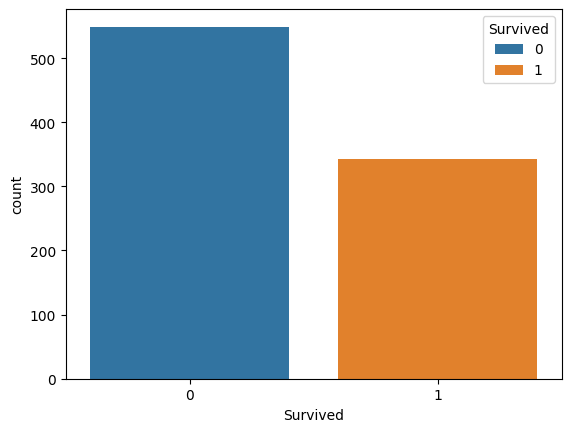

In [7]:
sns.countplot(x=df['Survived'], hue=df['Survived']); # hayatta kalan ve kalmayan sayısı

In [8]:
df['Survived'].value_counts() # her sınıftan kaç yolcu var

Survived
0    549
1    342
Name: count, dtype: int64

**Sonuç:** 549 yolcu hayatını kaybetmiş, 342 yolcu hayatta kalmış. Herkese 'hayatta kalmadı' diyen bir model bile %62 doğruluk alır; modellerimizin bunun belirgin şekilde üstüne çıkması gerekiyor.

In [9]:
df.groupby('Sex')['Survived'].mean() # cinsiyete göre hayatta kalma oranı

Sex
female    0.742038
male      0.188908
Name: Survived, dtype: float64

In [10]:
df.groupby('Pclass')['Survived'].mean() # yolcu sınıfına göre hayatta kalma oranı

Pclass
1    0.629630
2    0.472826
3    0.242363
Name: Survived, dtype: float64

**Sonuç:** Kadınların %74'ü, erkeklerin %19'u hayatta kalmış. 1. sınıf yolcuların %63'ü, 3. sınıf yolcuların %24'ü hayatta kalmış. Cinsiyet ve yolcu sınıfı en güçlü belirleyiciler gibi görünüyor.

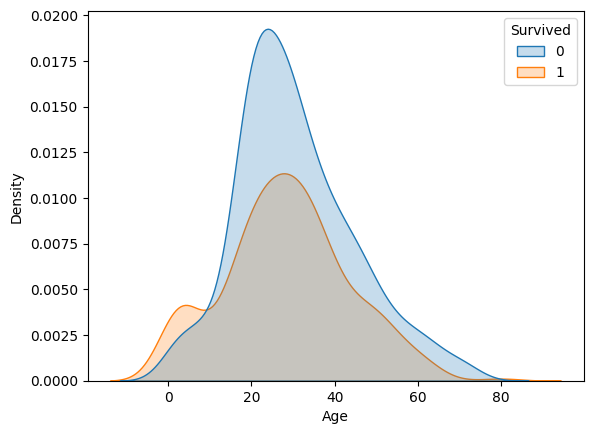

In [11]:
sns.kdeplot(x=df['Age'], hue=df['Survived'], fill=True); # yaşa göre hayatta kalma

**Sonuç:** Küçük çocuklarda (0-10 yaş) hayatta kalanlar daha fazla; 'önce kadınlar ve çocuklar' kuralı uygulanmış.

### Veri hazırlama

**Ne yapıyoruz:** Modelin kullanamayacağı sütunları siliyoruz. PassengerId sadece bir sıra numarası; Name ve Ticket her yolcu için farklı metinler; Cabin çoğunlukla boş. Embarked sütunundaki 2 boş değeri en çok tekrar eden limanla (mode) dolduruyoruz.

In [12]:
df=df.drop(['PassengerId','Name','Ticket','Cabin'], axis=1) # kullanılmayacak sütunlar
df['Embarked']=df['Embarked'].fillna(df['Embarked'].mode()[0]) # boş limanları en sık limanla doldur
df.head() # kalan sütunlar

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S


**Ne yapıyoruz:** Derslerdeki Pima örneğindeki gibi hedef sütunu silip kalan sütunları x, hedefi y olarak ayırıyoruz. Sex ve Embarked metin olduğu için derslerdeki `get_dummies` ile 0-1 sütunlara çeviriyoruz.

In [13]:
x=df.drop('Survived', axis=1) # Survived sütununu sil, kalanını x e eşitle
y=df[['Survived']] # hedef
x=pd.get_dummies(x, drop_first=True) # metin sütunlarını 0-1 sütunlara çevir
x.head() # özellikler

,Pclass,Age,SibSp,Parch,Fare,Sex_male,Embarked_Q,Embarked_S
0,3,22.0,1,0,7.2500,True,False,True
1,1,38.0,1,0,71.2833,False,False,False
2,3,26.0,0,0,7.9250,False,False,True
3,1,35.0,1,0,53.1000,False,False,True
4,3,35.0,0,0,8.0500,True,False,True


In [14]:
x_train, x_test, y_train, y_test=train_test_split(x,y, random_state=42, train_size=0.80) # %80 eğitim %20 test
x_train.shape, x_test.shape # eğitim ve test boyutu

((712, 8), (179, 8))

**Sonuç:** 712 yolcu eğitim, 179 yolcu test için ayrıldı.

**Ne yapıyoruz:** Age sütunundaki boş yaşları ortalama yaşla dolduruyoruz. Ortalamayı sadece eğitim verisinden hesaplıyoruz ve test verisini de aynı değerle dolduruyoruz; böylece test verisindeki yaşlar eğitime karışmıyor.

In [15]:
ort=x_train['Age'].mean() # eğitim verisinin yaş ortalaması
x_train['Age']=x_train['Age'].fillna(ort) # eğitim verisini doldur
x_test['Age']=x_test['Age'].fillna(ort) # test verisini aynı değerle doldur
x_train.isnull().sum().sum(), x_test.isnull().sum().sum() # kalan boş değer

(np.int64(0), np.int64(0))

**Ne yapıyoruz:** Derslerdeki Pima örneğinde StandardScaler bölmeden önce bütün veriye uygulanmıştı; bu, test verisinin ölçeklendirmeye karışması demek. Burada scaler'ı sadece eğitim verisiyle öğretiyoruz (`fit_transform`), test verisini aynı kuralla dönüştürüyoruz (`transform`).

In [16]:
from sklearn.preprocessing import StandardScaler # ölçeklendirme
sc=StandardScaler() # scaler
x_train_sc=sc.fit_transform(x_train) # eğitim verisiyle öğren ve dönüştür
x_test_sc=sc.transform(x_test) # test verisini aynı kuralla dönüştür

In [17]:
from tensorflow.keras.models import Sequential # katmanları sırayla dizen model
from tensorflow.keras.layers import Dense # tam bağlantılı katman
from tensorflow.keras.callbacks import EarlyStopping # erken durdurma
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report # başarı ölçüleri
sonuclar={} # modellerin test accuracy değerleri

**Ne yapıyoruz:** Derslerdeki Pima örneğinde model eğitildiği veriyle değerlendirilmişti (`model.evaluate(x,y)`); bu, modelin ezberini ölçer. Burada her modeli eğitimde hiç görmediği test verisiyle değerlendiriyoruz.

### Model 1: Derslerdeki Pima modeli, ölçeklendirme olmadan

**Ne yapıyoruz:** Derslerdeki Pima modelinin aynısını kuruyoruz: 7 gizli katman (80, 120, 64, 30, 16, 8, 4 nöron) ve iki sınıflı problem olduğu için son katmanda tek nöron ve sigmoid. Derslerde olduğu gibi önce ölçeklendirme yapmadan eğitiyoruz.

In [18]:
model1=Sequential() # boş model
model1.add(Dense(80, activation='relu')) # 1. katman 80 nöron
model1.add(Dense(120, activation='relu')) # 2. katman
model1.add(Dense(64, activation='relu')) # 3. katman
model1.add(Dense(30, activation='relu')) # 4. katman
model1.add(Dense(16, activation='relu')) # 5. katman
model1.add(Dense(8, activation='relu')) # 6. katman
model1.add(Dense(4, activation='relu')) # 7. katman
model1.add(Dense(1, activation='sigmoid')) # classification ve binary (1,0) ise son layer sigmoid
model1.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy']) # modeli derle
history1=model1.fit(x_train.astype(float), y_train, epochs=100, batch_size=32, validation_split=.10, verbose=0) # ölçeklenmemiş veriyle eğit
loss,sonuclar['1. Pima modeli, ölçeklendirmesiz']=model1.evaluate(x_test.astype(float), y_test, verbose=0) # test verisiyle ölç
sonuclar['1. Pima modeli, ölçeklendirmesiz'] # test accuracy

0.7709497213363647

**Sonuç:** Accuracy yaklaşık %77; hedefin altında. Ölçeklendirme yapılmadığında bilet ücreti (0-512) gibi büyük sayılı sütunlar, cinsiyet (0-1) gibi küçük sayılı sütunları ezdi ve sinir ağı iyi öğrenemedi. Sinir ağları rastgele başlangıçla eğitildiği için bu değer her çalıştırmada birkaç puan değişebilir.

### Model 2: Derslerdeki Pima modeli, StandardScaler ile

In [19]:
model2=Sequential() # aynı model
model2.add(Dense(80, activation='relu')) # 1. katman
model2.add(Dense(120, activation='relu')) # 2. katman
model2.add(Dense(64, activation='relu')) # 3. katman
model2.add(Dense(30, activation='relu')) # 4. katman
model2.add(Dense(16, activation='relu')) # 5. katman
model2.add(Dense(8, activation='relu')) # 6. katman
model2.add(Dense(4, activation='relu')) # 7. katman
model2.add(Dense(1, activation='sigmoid')) # çıkış
model2.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy']) # modeli derle
history2=model2.fit(x_train_sc, y_train, epochs=100, batch_size=32, validation_split=.10, verbose=0) # ölçeklenmiş veriyle eğit
loss,sonuclar['2. Pima modeli, StandardScaler']=model2.evaluate(x_test_sc, y_test, verbose=0) # test verisiyle ölç
sonuclar['2. Pima modeli, StandardScaler'] # test accuracy

0.8156424760818481

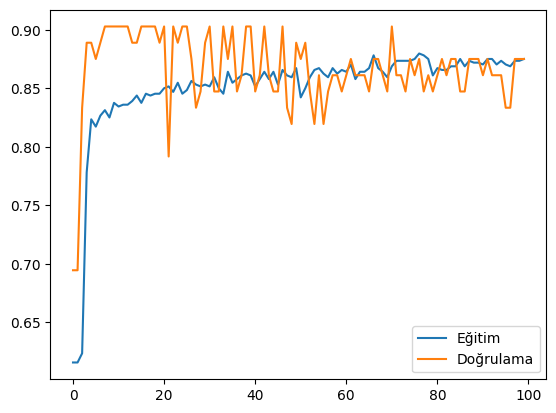

In [20]:
plt.plot(history2.history['accuracy'], label='Eğitim') # derslerdeki gibi eğitim doğruluğu
plt.plot(history2.history['val_accuracy'], label='Doğrulama') # doğrulama doğruluğu
plt.legend(); # açıklama kutusu

**Sonuç:** StandardScaler eklenince accuracy yaklaşık %81,6'ya çıktı ve hedef geçildi; aynı model sadece ölçeklendirme ile yaklaşık 4,5 puan iyileşti. Grafikte eğitim doğruluğu ilk epoch'larda hızla %83'e çıkıyor, sonra yavaşça %87-88'e yükseliyor. Doğrulama doğruluğu ise çok dalgalı (%79-90), çünkü doğrulama için eğitim verisinin sadece %10'u (71 yolcu) ayrılıyor; bir yolcu bile değeri 1,4 puan değiştiriyor. Doğrulama doğruluğu ilk 20 epoch'ta daha yüksek, sonra biraz düşüyor: model uzun eğitimde eğitim verisini ezberlemeye başlıyor.

### Model 3: Pima modeli, StandardScaler ve EarlyStopping

**Ne yapıyoruz:** Model 2'nin aynısına derslerdeki EarlyStopping'i ekliyoruz: doğrulama hatası 10 epoch boyunca iyileşmezse eğitim duruyor.

In [21]:
model3=Sequential() # aynı model
model3.add(Dense(80, activation='relu')) # 1. katman
model3.add(Dense(120, activation='relu')) # 2. katman
model3.add(Dense(64, activation='relu')) # 3. katman
model3.add(Dense(30, activation='relu')) # 4. katman
model3.add(Dense(16, activation='relu')) # 5. katman
model3.add(Dense(8, activation='relu')) # 6. katman
model3.add(Dense(4, activation='relu')) # 7. katman
model3.add(Dense(1, activation='sigmoid')) # çıkış
model3.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy']) # modeli derle
history3=model3.fit(x_train_sc, y_train, epochs=100, batch_size=32, validation_split=.10, verbose=0, callbacks=[EarlyStopping(monitor='val_loss', patience=10)]) # erken durdurmalı eğitim
loss,sonuclar['3. Pima modeli, EarlyStopping']=model3.evaluate(x_test_sc, y_test, verbose=0) # test verisiyle ölç
sonuclar['3. Pima modeli, EarlyStopping'], len(history3.history['loss']) # test accuracy ve kaç epoch eğitildiği

(0.8212290406227112, 23)

**Sonuç:** EarlyStopping ile accuracy yaklaşık %82,1. Eğitim 100 yerine yaklaşık 23 epoch'ta kendiliğinden durdu; model ezberlemeye başlamadan eğitim bitti ve sonuç Model 2'den biraz daha iyi oldu.

### Model 4: Küçük model

**Ne yapıyoruz:** 891 yolculuk küçük bir veri için 7 katmanlı model çok büyük olabilir. 2 gizli katmanlı (16 ve 8 nöron) küçük bir modeli EarlyStopping ile deniyoruz.

In [22]:
model4=Sequential() # boş model
model4.add(Dense(16, activation='relu')) # 1. katman
model4.add(Dense(8, activation='relu')) # 2. katman
model4.add(Dense(1, activation='sigmoid')) # çıkış
model4.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy']) # modeli derle
history4=model4.fit(x_train_sc, y_train, epochs=200, batch_size=32, validation_split=.10, verbose=0, callbacks=[EarlyStopping(monitor='val_loss', patience=10)]) # erken durdurmalı eğitim
loss,sonuclar['4. Küçük model (16-8)']=model4.evaluate(x_test_sc, y_test, verbose=0) # test verisiyle ölç
sonuclar['4. Küçük model (16-8)'] # test accuracy

0.8044692873954773

### Model 5: Orta boy model

In [23]:
model5=Sequential() # boş model
model5.add(Dense(64, activation='relu')) # 1. katman
model5.add(Dense(32, activation='relu')) # 2. katman
model5.add(Dense(16, activation='relu')) # 3. katman
model5.add(Dense(1, activation='sigmoid')) # çıkış
model5.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy']) # modeli derle
history5=model5.fit(x_train_sc, y_train, epochs=200, batch_size=32, validation_split=.10, verbose=0, callbacks=[EarlyStopping(monitor='val_loss', patience=10)]) # erken durdurmalı eğitim
loss,sonuclar['5. Orta model (64-32-16)']=model5.evaluate(x_test_sc, y_test, verbose=0) # test verisiyle ölç
sonuclar['5. Orta model (64-32-16)'] # test accuracy

0.826815664768219

**Sonuç:** Küçük model (16-8) yaklaşık %80,4, orta model (64-32-16) yaklaşık %82,7 aldı. İkisi de hedefi geçti. Derslerdeki 7 katmanlı büyük Pima modeli, daha küçük modellerden belirgin şekilde daha iyi değil; 891 yolculuk küçük bir veride büyük bir ağa gerek yok.

### Karşılaştırma: Logistic Regression

**Ne yapıyoruz:** Sinir ağlarının bu veride gerçekten avantaj sağlayıp sağlamadığını görmek için derslerdeki Logistic Regression modelini aynı veriyle deniyoruz.

In [24]:
from sklearn.linear_model import LogisticRegression # lojistik regresyon
L=LogisticRegression() # modeli oluştur
Ltahmin=L.fit(x_train_sc,y_train['Survived']).predict(x_test_sc) # eğit ve tahmin et
sonuclar['Logistic Regression (karşılaştırma)']=accuracy_score(y_test,Ltahmin) # doğruluk oranı
sonuclar['Logistic Regression (karşılaştırma)'] # test accuracy

0.8100558659217877

### Modellerin karşılaştırılması

In [25]:
metrics=pd.DataFrame({'Accuracy':sonuclar}).sort_values('Accuracy', ascending=False) # sonuç tablosu
metrics # modellerin accuracy değerleri

,Accuracy
5. Orta model (64-32-16),0.826816
"3. Pima modeli, EarlyStopping",0.821229
"2. Pima modeli, StandardScaler",0.815642
Logistic Regression (karşılaştırma),0.810056
4. Küçük model (16-8),0.804469
"1. Pima modeli, ölçeklendirmesiz",0.770950


**Sonuç:** 5 Keras modelinden 4'ü %80 hedefini geçti; sadece ölçeklendirme yapılmayan model (%77) altında kaldı. En iyi sonuçlar %82-83 civarında. Karşılaştırma için kurulan Logistic Regression %81,0 ile sinir ağlarına çok yakın: Titanic gibi küçük ve tablo şeklindeki bir veride derin öğrenme, basit modellere göre büyük bir avantaj sağlamıyor. Modeller arasındaki 1-2 puanlık farklar 2-3 yolcuya karşılık geliyor ve sinir ağlarının rastgeleliği yüzünden her çalıştırmada sıralama değişebilir. Projenin en net sonucu, StandardScaler'ın sinir ağları için önemi.

### Seçilen modelin değerlendirmesi: Model 3

**Ne yapıyoruz:** Derslerdeki Pima modelinin StandardScaler ve EarlyStopping eklenmiş halini (Model 3) ayrıntılı değerlendiriyoruz. Sinir ağı her yolcu için 0-1 arası bir olasılık veriyor; 0,5'ten büyükse 'hayatta kaldı' (1) kabul ediyoruz.

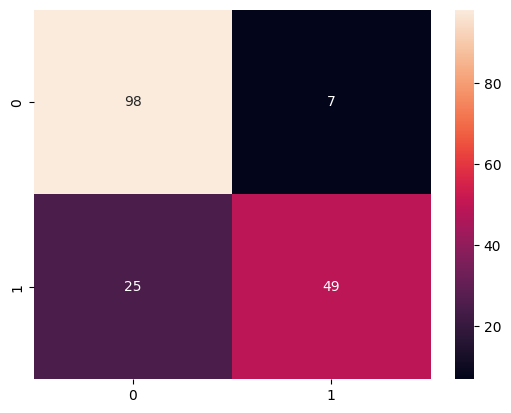

In [26]:
tahmin=(model3.predict(x_test_sc, verbose=0)>0.5).astype(int) # 0,5'ten büyükse hayatta kaldı
sns.heatmap(confusion_matrix(y_test,tahmin), annot=True); # satırlar gerçek, sütunlar tahmin

In [27]:
print(classification_report(y_test,tahmin)) # precision, recall, f1

              precision    recall  f1-score   support

           0       0.80      0.93      0.86       105
           1       0.88      0.66      0.75        74

    accuracy                           0.82       179
   macro avg       0.84      0.80      0.81       179
weighted avg       0.83      0.82      0.82       179



**Sonuç:** Model 3, 105 hayatını kaybeden yolcunun 98'ini (recall 0,93), 74 hayatta kalan yolcunun 49'unu (recall 0,66) doğru tahmin etti. Model 'hayatta kaldı' dediği yolcularda çok isabetli (precision 0,88), ama hayatta kalanların üçte birini kaçırıyor. Veride hayatını kaybedenler daha fazla olduğu için model şüpheli durumlarda 'hayatta kalmadı' demeye yatkın.

### Örnek tahmin

In [28]:
yolcular=pd.DataFrame([[1, 30, 0, 0, 100, False, False, False],[3, 30, 0, 0, 8, True, False, True]], columns=x_train.columns) # 1. sınıf kadın ve 3. sınıf erkek, 30 yaşında, yalnız
model3.predict(sc.transform(yolcular), verbose=0) # hayatta kalma olasılıkları

array([[0.97235775],
       [0.12840845]], dtype=float32)

**Sonuç:** 30 yaşında, yalnız seyahat eden, 1. sınıf kadın yolcunun hayatta kalma olasılığı yaklaşık %97; aynı yaşta, yalnız, 3. sınıf erkek yolcunun olasılığı yaklaşık %13. Model, EDA'da gördüğümüz 'önce kadınlar' kuralını ve 1. sınıfın avantajını öğrenmiş.

### Modeli kaydetme

In [29]:
model3.save('titanic_keras.keras') # modeli kaydet
import joblib # dosya kaydetme kütüphanesi
joblib.dump(sc,'titanic_scaler.pkl') # scaler'ı kaydet

['titanic_scaler.pkl']

In [30]:
from tensorflow.keras.models import load_model # kayıtlı modeli yükleme
yuklenen=load_model('titanic_keras.keras') # kaydedilen model çalışıyor mu test ediyoruz
(yuklenen.predict(x_test_sc[:5], verbose=0)>0.5).astype(int).ravel(), y_test['Survived'][:5].values # ilk 5 yolcu: tahmin ve gerçek

(array([0, 0, 0, 1, 0]), array([1, 0, 0, 1, 1]))

**Sonuç:** Kaydedilen model yüklendi ve tahmin yaptı. Yeni bir yolcu için önce aynı scaler ile ölçeklendirme yapılmalı.

## Sonuçların Değerlendirilmesi

Bu projede Titanic yolcularının hayatta kalıp kalmadığını, derslerdeki Pima Indians Diabetes örneğinin yöntemiyle Keras sinir ağlarıyla tahmin ettik.

| Model | Test accuracy |
|---|---|
| 5. Orta model (64-32-16), EarlyStopping | ~0.827 |
| 3. Pima modeli, StandardScaler ve EarlyStopping | ~0.821 |
| 2. Pima modeli, StandardScaler | ~0.816 |
| Logistic Regression (karşılaştırma) | 0.810 |
| 4. Küçük model (16-8), EarlyStopping | ~0.804 |
| 1. Pima modeli, ölçeklendirme olmadan | ~0.771 |

**Hedef accuracy > 0.80 idi; ulaşıldı.** 5 Keras modelinden 4'ü hedefi geçti.

Projeden çıkan sonuçlar:
- **StandardScaler sinir ağları için çok önemli:** Aynı Pima modeli ölçeklendirme olmadan %77, ölçeklendirmeyle %82 aldı.
- **EarlyStopping ezberlemeyi önlüyor:** Eğitim 100 epoch yerine yaklaşık 23 epoch'ta durdu ve sonuç biraz iyileşti.
- **Büyük model her zaman daha iyi değil:** Derslerdeki 7 katmanlı model, 2-3 katmanlı modellerden belirgin şekilde iyi olmadı.
- **Derin öğrenme küçük veride büyük avantaj sağlamıyor:** Basit Logistic Regression (%81) sinir ağlarına çok yakın sonuç verdi.

Hayatta kalmayı en çok belirleyen etkenler cinsiyet ve yolcu sınıfı. Seçilen model (Model 3) `titanic_keras.keras`, scaler `titanic_scaler.pkl` olarak kaydedildi.

## Kodun Değerlendirilmesi

Derslerdeki Pima örneğinin yapısı izlendi: x ve y ayrımı, Sequential model, Dense katmanlar, relu ve sigmoid aktivasyonları, binary_crossentropy, adam, epochs=100, batch_size=32, validation_split=0.10, StandardScaler ve history grafiği. Derslerdeki Pima kodundaki iki sorun düzeltildi:
1. StandardScaler bütün veriye değil, sadece eğitim verisine öğretildi; test verisi aynı kuralla dönüştürüldü.
2. Modeller eğitildikleri veriyle değil, ayrı tutulan test verisiyle değerlendirildi. Derslerdeki `model.evaluate(x,y)` eğitim verisiyle yapıldığı için modelin ezberini ölçüyordu.

Boş yaşlar da sadece eğitim verisinin ortalamasıyla dolduruldu.

## Eksikler ve Sınırlılıklar

- Veri küçük (891 yolcu, testte 179). Bir yolcu accuracy'yi 0,56 puan değiştiriyor; modeller arasındaki küçük farklar güvenilir değil.
- Sinir ağları rastgele başlangıç ağırlıklarıyla eğitildiği için ~ işaretli değerler her çalıştırmada birkaç puan değişebilir.
- Name sütunundaki unvanlar (Mr, Mrs, Miss, Master) ve Cabin sütunundaki kat bilgisi kullanılmadı; bu bilgiler modele eklenirse sonuç iyileşebilir.
- Boş yaşlar tek bir ortalama değerle dolduruldu.
- TensorFlow ilk yüklendiğinde bilgi mesajları yazdırıyor; bunlar hata değil.